# Double descent — book graphics 7: bias–variance across degrees 1–5

Still versions of the degree-by-degree bias–variance section of `p65_68_rewrite.py`.

**Ensembles** (reproduce the video's `fits_*_order_oct_*.npy` files exactly, seeds 0…N−1):

| degree | points per dataset (train) | datasets |
|---|---|---|
| 1 | 60 (30) | 256 |
| 2 | 10 (5) | 50 |
| 3, 4, 5 | 10 (5) | 128 |

Degree 1 uses more points so the trade-off reads clearly (caption footnote).

**Exports**

- `mean_std_deg{d}.svg` — mean fit ± 1 std band over the underlying function, one per degree (clipped to `YLIM`; `_unclipped` for degrees in `UNCLIP_DEGREES`)
- `all_fits_deg{d}.svg` — all fits in the ensemble, thin (companion)
- `mse_breakdown.svg` — test MSE vs degree with each point's bar split into bias², variance and irreducible error

**Decomposition.** For $y = f(x) + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma^2)$, and a fit $\hat f_D$ trained on a random dataset $D$:

$$
\mathbb{E}_{D,\varepsilon}\big[(y - \hat f_D(x))^2\big]
= \underbrace{\big(f(x) - \mathbb{E}_D[\hat f_D(x)]\big)^2}_{\text{bias}^2}
+ \underbrace{\mathbb{E}_D\big[(\hat f_D(x) - \mathbb{E}_D[\hat f_D(x)])^2\big]}_{\text{variance}}
+ \underbrace{\sigma^2}_{\text{irreducible}}
$$

The notebook estimates each term from the ensemble (mean over datasets, then over $x \in [-2, 2]$) and prints them. **Caveat:** with 5 training points the degree-3–5 variances are enormous (a handful of near-collinear datasets explode), so the true stacked bars can't share an axis with degrees 1–2. `BAR_MODE` chooses how the bars are drawn — see the config.


## 1. Config

In [1]:
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'
YELLOW      = '#fcc947'
LT_PURPLE   = '#b2c2e4'
PURPLE      = '#7e5b76'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE
FIT_COLORS   = {1: GREEN, 2: BLUE, 3: RED, 4: PINK, 5: PURPLE}   # per-degree: mean line, std band, thin fits
STD_ALPHA    = 0.2
ALL_FITS_ALPHA = 0.4

BIAS_COLOR   = PINK      # bar segments
VAR_COLOR    = BLUE
NOISE_COLOR  = GREEN

# ── Data / ensembles (matches the video's npy recipes) ─────────────────────
NOISE_LEVEL = 0.2
X_MIN, X_MAX = -2.0, 2.0
TRAIN_FRAC  = 0.5
def f(x): return 0.5 * x**2
DEGREES     = [1, 2, 3, 4, 5]
ENSEMBLE    = {           # degree: (points per dataset, number of datasets)
    1: (60, 256),
    2: (10, 50),
    3: (10, 128),
    4: (10, 128),
    5: (10, 128),
}

# ── MSE / breakdown panel ──────────────────────────────────────────────────
MSE_SEED        = 428             # the single dataset whose test MSE dots the video shows (10 points, 5 train)
MSE_SEED_POINTS = 10
MSE_SHOW_TRAIN  = False           # also draw the train-MSE dots
BAR_MODE        = 'fractions'     # 'fractions': bars reach the seed-428 test-MSE dot, split by the ensemble's
                                  #              bias2 : variance : sigma2 fractions (honest proportions, video heights)
                                  # 'manual':    same heights, split by BAR_FRACTIONS below (the video's hand-set values)
                                  # 'absolute':  bars are the true ensemble bias2 + variance + sigma2 (off the chart for 3-5)
BAR_FRACTIONS   = {1: (0.85, 0.10, 0.06), 2: (0.10, 0.60, 0.30), 3: (0.01, 0.94, 0.05),
                   4: (0.01, 0.96, 0.03), 5: (0.01, 0.94, 0.05)}   # (bias2, variance, noise) as in p65_68_rewrite.py
BAR_WIDTH       = 0.3
BAR_ALPHA       = 1.0
MSE_YLIM        = None            # None = auto
MSE_LOG_Y       = False           # handy with BAR_MODE='absolute'

# ── Curve panels ───────────────────────────────────────────────────────────
AX_WIDTH_IN     = 4.0
AX_HEIGHT_IN    = 3.4
MARGIN_IN       = 0.6
LINEWIDTH       = 2.0
ALL_FITS_LINEWIDTH = 0.6
AXIS_LINEWIDTH  = 1.0
DOT_SIZE        = 36
FONTSIZE        = 10
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)
UNCLIP_DEGREES  = [1, 2]          # degrees that also get an _unclipped export (3-5 bands are ±15 .. ±10000 units)
UNCLIP_YLIM     = {}              # per-degree override, e.g. {3: (-5, 8)}; otherwise widen to contain the ±1 std band
UNCLIP_PAD      = 0.25
X_TICK_STEP     = 1.0
Y_TICK_STEP     = 1.0
SPINES          = 'lb'
SHOW_TICKS      = True
CURVE_ALPHA     = 0.5
CURVE_LINESTYLE = '-'
SHOW_MEAN_LINE  = True
TRANSPARENT     = True

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = False
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance_degrees')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers

In [2]:
def legendre_features(x, degree, x_min=X_MIN, x_max=X_MAX):
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    return scipy.special.eval_legendre(np.arange(degree + 1)[:, None], x_scaled).T

def fit_legendre_pinv(x_train, y_train, degree):
    return np.linalg.pinv(legendre_features(x_train, degree)) @ y_train

def eval_legendre_poly(beta, x, degree):
    return legendre_features(x, degree) @ beta

def get_noisy_data(n_points, noise_level=NOISE_LEVEL, random_seed=0):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y

def split(x, y, n_points):
    n_train = int(np.floor(n_points * TRAIN_FRAC))
    return x[:n_train], y[:n_train], x[n_train:], y[n_train:]


## 3. Ensembles + decomposition

In [3]:
all_x = np.linspace(X_MIN, X_MAX, 128)
all_y = f(all_x)
sigma2 = NOISE_LEVEL**2

ens = {}
for d in DEGREES:
    n_pts, n_sets = ENSEMBLE[d]
    fits = []
    for seed in range(n_sets):
        x, y = get_noisy_data(n_pts, random_seed=seed)
        x_tr, y_tr, _, _ = split(x, y, n_pts)
        fits.append(eval_legendre_poly(fit_legendre_pinv(x_tr, y_tr, d), all_x, d))
    fits = np.array(fits)
    mean_fit = fits.mean(0); std_fit = fits.std(0)
    ens[d] = dict(fits=fits, mean=mean_fit, std=std_fit,
                  bias2=np.mean((all_y - mean_fit)**2),        # E_x[(f - E_D f_hat)^2]
                  var=np.mean((fits - mean_fit)**2))           # E_x E_D[(f_hat - E_D f_hat)^2]

# the single dataset whose MSE dots the video shows
x, y = get_noisy_data(MSE_SEED_POINTS, random_seed=MSE_SEED)
x_tr, y_tr, x_te, y_te = split(x, y, MSE_SEED_POINTS)
single = {}
for d in DEGREES:
    beta = fit_legendre_pinv(x_tr, y_tr, d)
    single[d] = dict(train_mse=np.mean((y_tr - eval_legendre_poly(beta, x_tr, d))**2),
                     test_mse =np.mean((y_te - eval_legendre_poly(beta, x_te, d))**2))

print(f"{'deg':>3} {'n':>3} {'N':>4} | {'bias^2':>10} {'variance':>14} {'sigma^2':>8} {'sum':>14} | {'fractions b/v/n':>22} | {'seed-428 test MSE':>17}")
for d in DEGREES:
    e = ens[d]; tot = e['bias2'] + e['var'] + sigma2
    fr = (e['bias2'] / tot, e['var'] / tot, sigma2 / tot)
    print(f"{d:>3} {ENSEMBLE[d][0]:>3} {ENSEMBLE[d][1]:>4} | {e['bias2']:>10.4f} {e['var']:>14.3f} {sigma2:>8.3f} {tot:>14.3f} | "
          f"{fr[0]:>6.1%} {fr[1]:>6.1%} {fr[2]:>6.1%}  | {single[d]['test_mse']:>17.4f}")


deg   n    N |     bias^2       variance  sigma^2            sum |        fractions b/v/n | seed-428 test MSE
  1  60  256 |     0.3675          0.040    0.040          0.447 |  82.2%   8.9%   8.9%  |            0.6916
  2  10   50 |     0.0018          0.062    0.040          0.104 |   1.7%  59.9%  38.4%  |            0.0794
  3  10  128 |     0.0747         49.320    0.040         49.434 |   0.2%  99.8%   0.1%  |            0.7270
  4  10  128 | 11833.4713    7224443.446    0.040    7236276.958 |   0.2%  99.8%   0.0%  |            1.3285
  5  10  128 |   903.4059     239695.007    0.040     240598.453 |   0.4%  99.6%   0.0%  |            0.6941


## 4. Renderers

In [4]:
X_IN_PER_UNIT = AX_WIDTH_IN  / (XLIM[1] - XLIM[0])
Y_IN_PER_UNIT = AX_HEIGHT_IN / (YLIM[1] - YLIM[0])

def exact_axes(width_in, height_in, margin=MARGIN_IN):
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

# ── curve panels ───────────────────────────────────────────────────────────
def curve_ylim(d, clip, kind):
    if clip:
        return YLIM
    if d in UNCLIP_YLIM:
        return UNCLIP_YLIM[d]
    e = ens[d]
    lo, hi = (e['fits'].min(), e['fits'].max()) if kind == 'all_fits' else ((e['mean'] - e['std']).min(), (e['mean'] + e['std']).max())
    return (min(YLIM[0], lo - UNCLIP_PAD), max(YLIM[1], hi + UNCLIP_PAD))

def draw_curves(ax, d, kind='mean_std', clip=True):
    """kind: 'mean_std' | 'all_fits'"""
    e = ens[d]; col = FIT_COLORS[d]
    ylim = curve_ylim(d, clip, kind)
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE, alpha=CURVE_ALPHA,
            zorder=3, solid_capstyle='round')
    if kind == 'all_fits':
        for c in e['fits']:
            ax.plot(all_x, c, color=col, lw=ALL_FITS_LINEWIDTH, alpha=ALL_FITS_ALPHA, zorder=2)
    else:
        ax.fill_between(all_x, e['mean'] - e['std'], e['mean'] + e['std'], color=col, alpha=STD_ALPHA, lw=0, zorder=1)
        if SHOW_MEAN_LINE:
            ax.plot(all_x, e['mean'], color=col, lw=LINEWIDTH, zorder=4, solid_capstyle='round')
    ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    style_ax(ax)

def curves_figure(d, kind='mean_std', clip=True):
    ylim = curve_ylim(d, clip, kind)
    fig, ax = exact_axes(AX_WIDTH_IN, (ylim[1] - ylim[0]) * Y_IN_PER_UNIT)
    draw_curves(ax, d, kind, clip)
    return fig, ax

# ── MSE breakdown panel ────────────────────────────────────────────────────
def bar_segments(d):
    """(bias2, variance, noise) segment heights for degree d, per BAR_MODE."""
    e = ens[d]
    if BAR_MODE == 'absolute':
        return e['bias2'], e['var'], sigma2
    total = single[d]['test_mse']
    if BAR_MODE == 'manual':
        fr = np.array(BAR_FRACTIONS[d], float); fr = fr / fr.sum()
    else:
        fr = np.array([e['bias2'], e['var'], sigma2]); fr = fr / fr.sum()
    return tuple(total * fr)

def draw_mse(ax):
    degs = np.array(DEGREES)
    for d in DEGREES:
        b, v, n = bar_segments(d)
        ax.bar(d, b, BAR_WIDTH, bottom=0,     color=BIAS_COLOR,  alpha=BAR_ALPHA, lw=0, zorder=2)
        ax.bar(d, v, BAR_WIDTH, bottom=b,     color=VAR_COLOR,   alpha=BAR_ALPHA, lw=0, zorder=2)
        ax.bar(d, n, BAR_WIDTH, bottom=b + v, color=NOISE_COLOR, alpha=BAR_ALPHA, lw=0, zorder=2)
    tops = np.array([sum(bar_segments(d)) for d in DEGREES])
    if BAR_MODE != 'absolute':
        ax.scatter(degs, [single[d]['test_mse'] for d in DEGREES], s=DOT_SIZE, color=TEST_COLOR, zorder=4, linewidths=0)
        if MSE_SHOW_TRAIN:
            ax.scatter(degs, [single[d]['train_mse'] for d in DEGREES], s=DOT_SIZE, color=TRAIN_COLOR, zorder=4, linewidths=0)
    ax.set_xlim(degs.min() - 0.5, degs.max() + 0.5)
    ax.set_xticks(degs)
    if MSE_LOG_Y:
        ax.set_yscale('log')
    elif MSE_YLIM is None:
        ax.set_ylim(0, 1.1 * tops.max())
    else:
        ax.set_ylim(*MSE_YLIM)
    style_ax(ax)

def mse_figure():
    fig, ax = exact_axes(AX_WIDTH_IN, AX_HEIGHT_IN)
    draw_mse(ax)
    return fig, ax


## 5. Preview

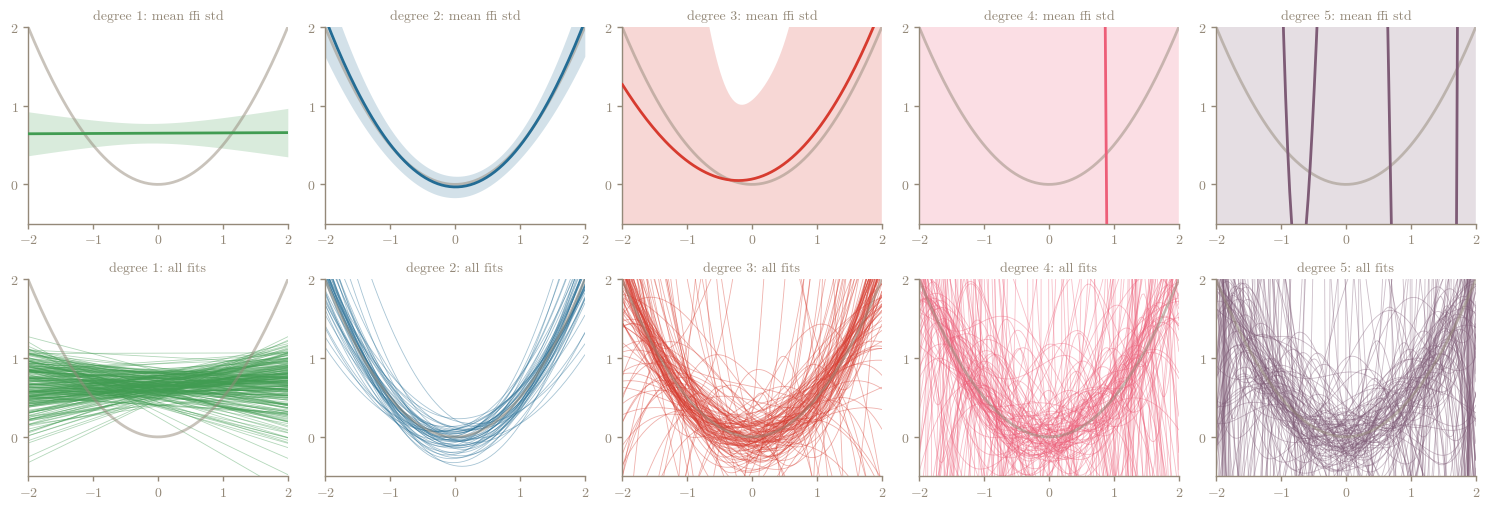

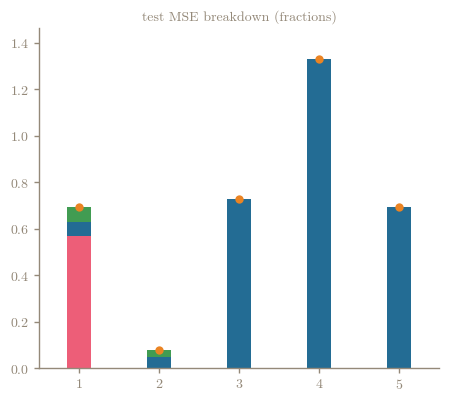

In [5]:
fig, axes = plt.subplots(2, len(DEGREES), figsize=(3.0 * len(DEGREES), 5.2))
for j, d in enumerate(DEGREES):
    draw_curves(axes[0, j], d, 'mean_std');  axes[0, j].set_title(f'degree {d}: mean ± std', color=AXIS_COLOR, fontsize=FONTSIZE)
    draw_curves(axes[1, j], d, 'all_fits');  axes[1, j].set_title(f'degree {d}: all fits', color=AXIS_COLOR, fontsize=FONTSIZE)
plt.tight_layout(); plt.show()

fig, ax = mse_figure(); ax.set_title(f'test MSE breakdown ({BAR_MODE})', color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()


## 6. Export

In [6]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    for d in DEGREES:
        for kind in ('mean_std', 'all_fits'):
            fig, _ = curves_figure(d, kind, clip=True);  save(fig, f'{kind}_deg{d}')
            if d in UNCLIP_DEGREES:
                fig, _ = curves_figure(d, kind, clip=False); save(fig, f'{kind}_deg{d}_unclipped')
    fig, _ = mse_figure(); save(fig, f'mse_breakdown_{BAR_MODE}')
    print('saved to', OUT_DIR)
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/bias_variance_degrees
   all_fits_deg1.svg
   all_fits_deg1_unclipped.svg
   all_fits_deg2.svg
   all_fits_deg2_unclipped.svg
   all_fits_deg3.svg
   all_fits_deg4.svg
   all_fits_deg5.svg
   mean_std_deg1.svg
   mean_std_deg1_unclipped.svg
   mean_std_deg2.svg
   mean_std_deg2_unclipped.svg
   mean_std_deg3.svg
   mean_std_deg4.svg
   mean_std_deg5.svg
   mse_breakdown_fractions.svg
